In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold

X, y = load_diabetes(return_X_y=True)
model = LinearRegression()
print(X.shape, y.shape)

(442, 10) (442,)


In [2]:
split_scores = []
for seed in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    model.fit(X_tr, y_tr)
    r2 = model.score(X_te, y_te)
    split_scores.append(r2)
    print(f"seed {seed}: test R² = {r2:.3f}")

print(f"\nLowest: {min(split_scores):.3f}   Highest: {max(split_scores):.3f}")

seed 0: test R² = 0.332
seed 1: test R² = 0.438
seed 2: test R² = 0.440
seed 3: test R² = 0.416
seed 4: test R² = 0.461
seed 5: test R² = 0.527
seed 6: test R² = 0.458
seed 7: test R² = 0.404
seed 8: test R² = 0.497
seed 9: test R² = 0.585

Lowest: 0.332   Highest: 0.585


In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=kf, scoring="r2")

for i, s in enumerate(cv_scores, 1):
    print(f"fold {i}: R² = {s:.3f}")
print(f"\n5-fold CV: mean R² = {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

fold 1: R² = 0.453
fold 2: R² = 0.573
fold 3: R² = 0.391
fold 4: R² = 0.584
fold 5: R² = 0.391

5-fold CV: mean R² = 0.478 ± 0.085


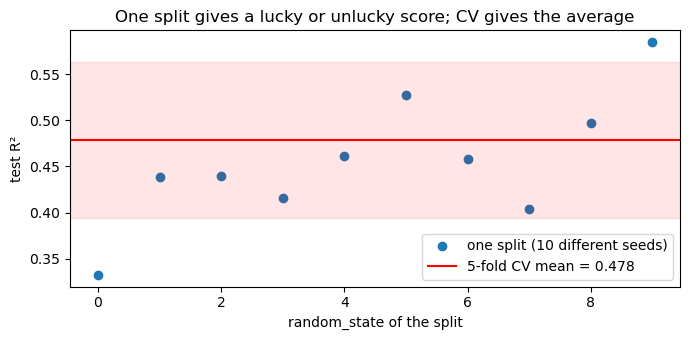

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(range(10), split_scores, label="one split (10 different seeds)")
ax.axhline(cv_scores.mean(), color="red", label=f"5-fold CV mean = {cv_scores.mean():.3f}")
ax.axhspan(cv_scores.mean() - cv_scores.std(), cv_scores.mean() + cv_scores.std(), color="red", alpha=0.1)
ax.set_xlabel("random_state of the split")
ax.set_ylabel("test R²")
ax.set_title("One split gives a lucky or unlucky score; CV gives the average")
ax.legend()
plt.tight_layout()
plt.show()